In [1]:
import numpy as np
from scipy.fft import dst, idst
import matplotlib.pyplot as plt
from struct import unpack, pack

In [2]:
f = open("Wildlife.wmv", "rb")
lenchunk = 0x1_00_00
chunk = f.read(lenchunk)
x = unpack("<" + "b" * lenchunk, chunk)
x = np.array(x)
x

array([ 48,  38, -78, ..., -88, -23,  66], shape=(65536,))

In [3]:
coef = dst(x, n=lenchunk)
ncoef = min(0x7F / coef.max(), -0x80 / coef.min())
coef *= ncoef
coef = np.rint(coef).astype(int)
unpack("<d", pack("<d", ncoef))[0], coef.max(), coef.min()

(0.00028006880071123756, np.int64(127), np.int64(-124))

In [4]:
coef = coef / ncoef
reconstructed = idst(coef, n=lenchunk)
reconstructed = np.rint(reconstructed).astype(np.int64)
reconstructed

array([ 47,  39, -74, ..., -87, -20,  63], shape=(65536,))

In [5]:
(np.abs(x - reconstructed)).sum()

np.int64(148634)

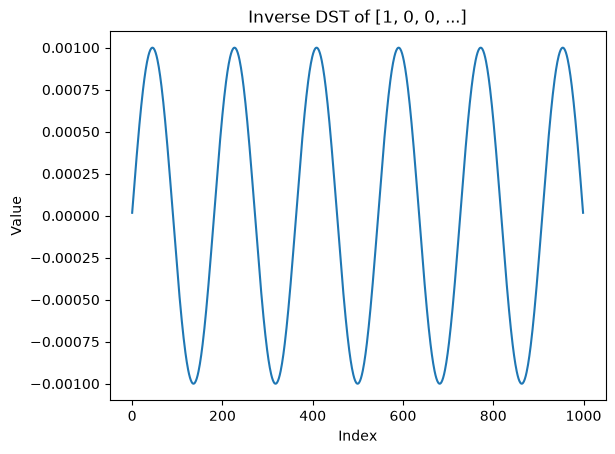

In [6]:
a = np.zeros(1000)
a[10] = 1

result = idst(a)
plt.plot(result)
plt.xlabel("Index")
plt.ylabel("Value")
plt.title("Inverse DST of [1, 0, 0, ...]")
plt.show()

In [7]:
import heapq
from itertools import count

# 값 0은 256회, 값 255는 1회 등장
frequencies = {value: 256 - value for value in range(256)}

heap = []
order = count()

for value, frequency in frequencies.items():
    heapq.heappush(heap, (frequency, next(order), ("leaf", value)))

while len(heap) > 1:
    freq1, _, left = heapq.heappop(heap)
    freq2, _, right = heapq.heappop(heap)
    heapq.heappush(
        heap,
        (freq1 + freq2, next(order), ("node", left, right))
    )

root = heap[0][2]
codes = {}

def build_codes(node, prefix=""):
    if node[0] == "leaf":
        codes[node[1]] = prefix or "0"
        return
    build_codes(node[1], prefix + "0")
    build_codes(node[2], prefix + "1")

build_codes(root)

shortest_length = min(map(len, codes.values()))
longest_length = max(map(len, codes.values()))

print("가장 짧은 코드:")
for value, code in codes.items():
    if len(code) == shortest_length:
        print(f"값 {value}, 코드 {code}, 길이 {len(code)}")

print("\n가장 긴 코드:")
for value, code in codes.items():
    if len(code) == longest_length:
        print(f"값 {value}, 코드 {code}, 길이 {len(code)}")

가장 짧은 코드:
값 63, 코드 0000000, 길이 7
값 62, 코드 0000001, 길이 7
값 61, 코드 0000010, 길이 7
값 60, 코드 0000100, 길이 7
값 59, 코드 0000101, 길이 7
값 58, 코드 0000110, 길이 7
값 57, 코드 0001000, 길이 7
값 56, 코드 0001001, 길이 7
값 55, 코드 0001010, 길이 7
값 54, 코드 0001100, 길이 7
값 53, 코드 0001101, 길이 7
값 52, 코드 0001110, 길이 7
값 51, 코드 0010000, 길이 7
값 50, 코드 0010001, 길이 7
값 49, 코드 0010010, 길이 7
값 48, 코드 0010100, 길이 7
값 47, 코드 0010101, 길이 7
값 46, 코드 0010110, 길이 7
값 45, 코드 0011000, 길이 7
값 44, 코드 0011001, 길이 7
값 43, 코드 0011010, 길이 7
값 42, 코드 0011100, 길이 7
값 41, 코드 0011101, 길이 7
값 40, 코드 0011110, 길이 7
값 39, 코드 0100000, 길이 7
값 38, 코드 0100001, 길이 7
값 37, 코드 0100010, 길이 7
값 36, 코드 0100100, 길이 7
값 35, 코드 0100101, 길이 7
값 34, 코드 0100110, 길이 7
값 33, 코드 0101000, 길이 7
값 32, 코드 0101001, 길이 7
값 31, 코드 0101010, 길이 7
값 30, 코드 0101100, 길이 7
값 29, 코드 0101101, 길이 7
값 28, 코드 0101110, 길이 7
값 27, 코드 0110000, 길이 7
값 26, 코드 0110001, 길이 7
값 25, 코드 0110010, 길이 7
값 24, 코드 0110100, 길이 7
값 23, 코드 0110101, 길이 7
값 22, 코드 0110110, 길이 7
값 21, 코드 0111000, 길이 7
값